In [ ]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


Coercion summary (new NaNs introduced by coercion):
  shallow_depth_s: +0 NaNs
  Deep_depth_s: +0 NaNs
  Deep_depth_t: +0 NaNs
  chlorophyll_depth: +0 NaNs
Examples of original values coerced to NaN (up to 5 examples per column):
  shallow_depth_s: []
  Deep_depth_s: []
  Deep_depth_t: []
  chlorophyll_depth: []
Dropped 2 rows with NaNs in required columns (remaining 600 rows).
Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):
     shallow_depth_s  Deep_depth_s  Deep_depth_t  chlorophyll_depth  \
170            0.100           NaN         3.463              0.724   
601            9.431        13.026           NaN              4.648   

       drop_reasons  
170  [Deep_depth_s]  
601  [Deep_depth_t]  
Saved cleaned data to 'data_cleaned.csv'
Original DataFrame shape: (602, 10)
DataFrame shape after coercion+outlier removal: (505, 10)


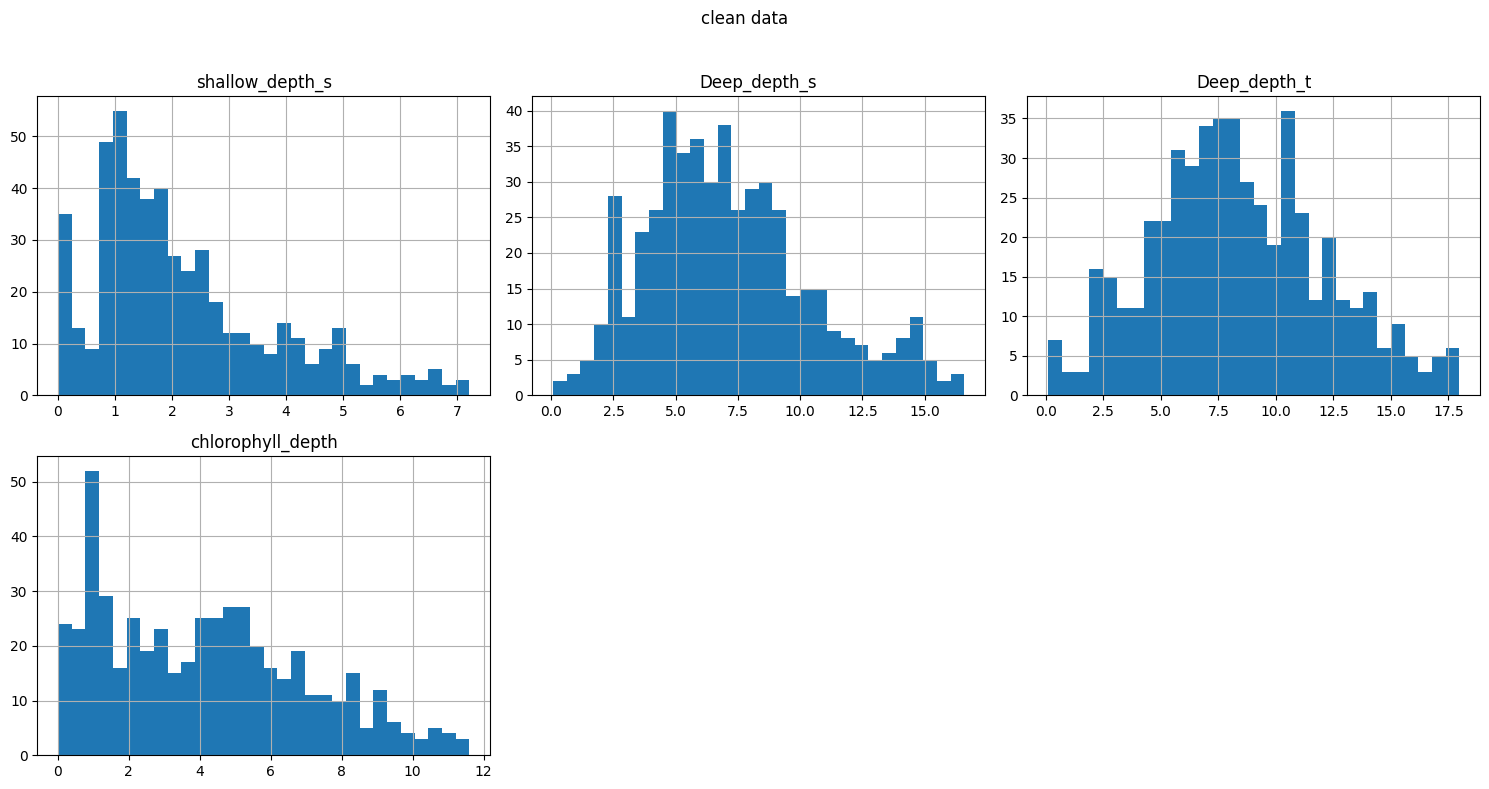

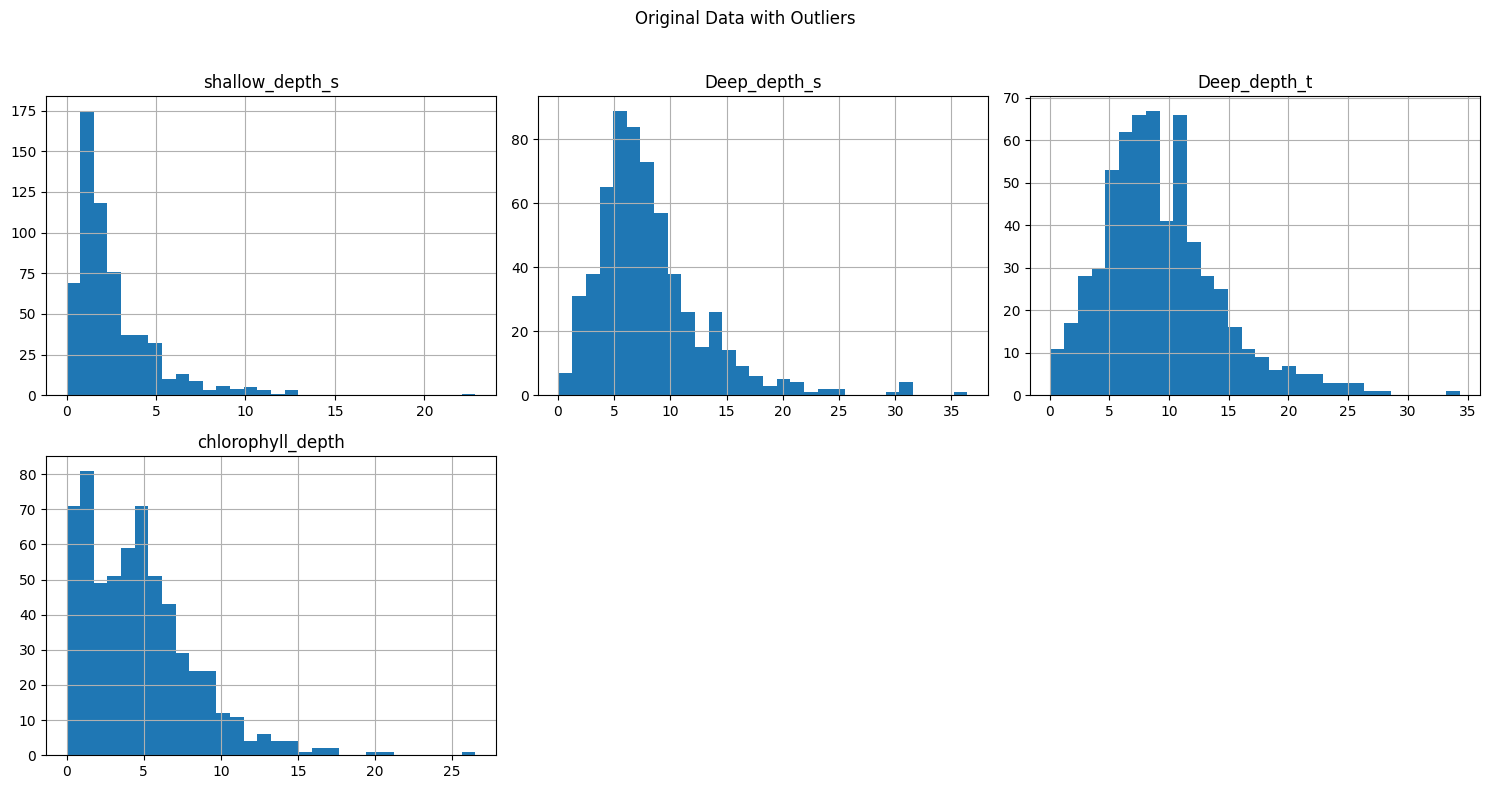

In [ ]:

# 2. Load and Prepare Your Data
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Load data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

# Feature and target columns (ensure these match your CSV headers)
feature_cols = ['shallow_depth_s', 'deep_depth_s', 'Deep_depth_t']
target_col = 'chlorophyll_depth'


def remove_outliers(df):
    """
    Removes rows containing outliers in the specified columns using the Z-score method.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]
    present_cols = [c for c in cols_to_check if c in df_cleaned.columns]
    missing_cols = [c for c in cols_to_check if c not in df_cleaned.columns]
    if missing_cols:
        print(f"Warning: Column(s) not found in the DataFrame and will be skipped: {missing_cols}")

    # Ensure we don't try to z-score constant or empty columns
    for col in present_cols:
        # coerce object columns to numeric where possible
        if df_cleaned[col].dtype == object:
            df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')
        if df_cleaned[col].dropna().nunique() <= 1:
            continue
        # compute zscore safely
        try:
            z = stats.zscore(df_cleaned[col].astype(float))
        except Exception:
            continue
        outlier_mask = np.abs(z) > 2  # adjust threshold if desired
        df_cleaned = df_cleaned[~outlier_mask]

    return df_cleaned


def coerce_and_clean_numeric(df, cols, target_col):
    """Coerce listed columns to numeric, replace infs, drop rows with NaNs, and provide diagnostics.

    Returns the cleaned DataFrame (rows kept). Also saves dropped rows to 'dropped_rows_inspection.csv'.
    """
    df2 = df.copy()
    converted = {}
    coercion_examples = {}

    for c in cols + [target_col]:
        if c in df2.columns:
            before_na = df2[c].isna().sum()
            # attempt coercion and capture examples of values that fail
            coerced = pd.to_numeric(df2[c], errors='coerce')
            coerced_mask = df2[c].notna() & coerced.isna()
            coercion_examples[c] = df2.loc[coerced_mask, c].head(5).tolist()
            df2[c] = coerced
            after_na = df2[c].isna().sum()
            converted[c] = after_na - before_na

    # Replace inf values with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    print("Coercion summary (new NaNs introduced by coercion):")
    for k, v in converted.items():
        print(f"  {k}: +{v} NaNs")

    print("Examples of original values coerced to NaN (up to 5 examples per column):")
    for k, v in coercion_examples.items():
        print(f"  {k}: {v}")

    present_cols = [c for c in cols + [target_col] if c in df2.columns]
    before = df2.shape[0]

    # identify rows that will be dropped and keep a copy for diagnostics
    dropped_rows = df2[df2[present_cols].isnull().any(axis=1)].copy() if present_cols else df2.iloc[0:0].copy()
    df2_kept = df2.dropna(subset=present_cols) if present_cols else df2.copy()
    after = df2_kept.shape[0]

    print(f"Dropped {before - after} rows with NaNs in required columns (remaining {after} rows).")

    if not dropped_rows.empty:
        # summarize drop reasons per-row
        def reasons(row):
            return [col for col in present_cols if pd.isna(row[col])]
        dropped_rows['drop_reasons'] = dropped_rows.apply(reasons, axis=1)
        # save dropped rows for inspection
        try:
            dropped_rows.to_csv('dropped_rows_inspection.csv', index=False)
            print("Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):")
        except Exception as e:
            print("Failed to save dropped_rows_inspection.csv:", e)
        display_cols = [c for c in present_cols if c in dropped_rows.columns]
        print(dropped_rows.head()[display_cols + ['drop_reasons']])

    return df2_kept


# Apply cleaning and outlier removal
if 'data' in locals():
    data_numeric = coerce_and_clean_numeric(data, feature_cols, target_col)
    data_cleaned = remove_outliers(data_numeric)
    # Save cleaned data for inspection
    try:
        data_cleaned.to_csv('data_cleaned.csv', index=False)
        print("Saved cleaned data to 'data_cleaned.csv'")
    except Exception as e:
        print("Failed to save data_cleaned.csv:", e)

    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after coercion+outlier removal:", data_cleaned.shape)
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    columns_to_plot = [c for c in feature_cols + [target_col] if c in data.columns]
    if not columns_to_plot:
        print("No columns available to plot.")
        return
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# If data_cleaned exists, plot histograms
if 'data_cleaned' in locals():
    plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
if 'data' in locals():
    plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")


2025-12-30 16:22:32.998362: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-30 16:22:33.477775: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-12-30 16:22:35.603249: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):
/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not p

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 24.0003 - val_loss: 15.4242
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 22.4152 - val_loss: 15.3468
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 21.0944 - val_loss: 15.5722
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 19.7952 - val_loss: 13.2279
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 19.6372 - val_loss: 13.8516
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 18.6134 - val_loss: 14.3964
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 16.7127 - val_loss: 13.2866
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 16.2411 - val_loss: 12.2811
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 16.2914 - val_loss: 12.0736
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 14.5020 - val_loss: 11.5109
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.4609 - val_loss: 11.7188
Epoch 12/100
12/12 ━━━━━━━━━━━

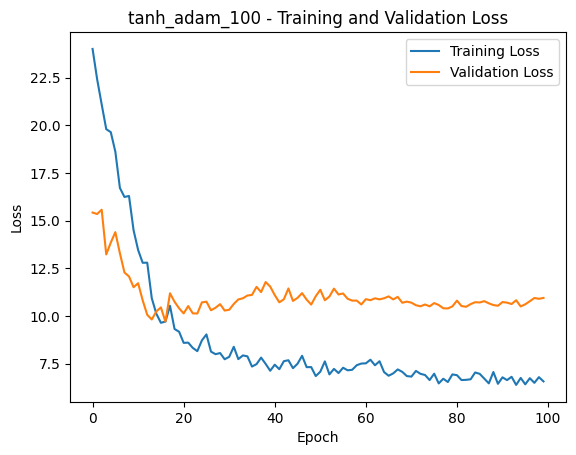

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 22.7240 - val_loss: 15.9339
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 21.5131 - val_loss: 13.9893
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 20.6711 - val_loss: 13.5191
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 20.6774 - val_loss: 14.4338
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 19.8863 - val_loss: 14.4889
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 18.6253 - val_loss: 12.8589
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 17.8339 - val_loss: 13.4785
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 16.5079 - val_loss: 12.0337
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 15.6107 - val_loss: 13.1622
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 14.9569 - val_loss: 12.4627
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 13.7950 - val_loss: 12.2572
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s

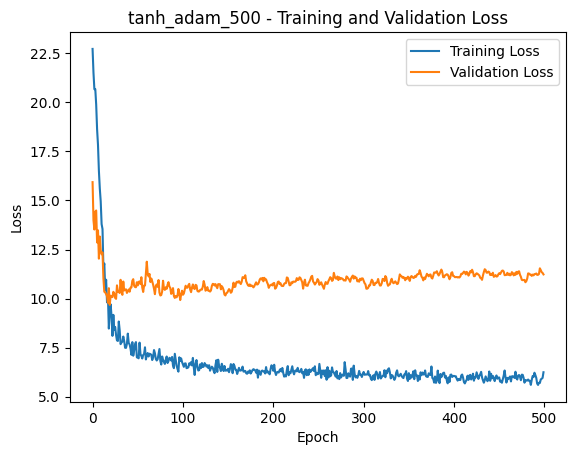

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 18.8162 - val_loss: 11.7349
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.2925 - val_loss: 11.8977
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 9.8567 - val_loss: 11.3400
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 9.0880 - val_loss: 10.1694
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 8.0142 - val_loss: 11.6133
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 8.0434 - val_loss: 10.6062
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.5018 - val_loss: 10.9871
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 8.1825 - val_loss: 10.6261
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.6867 - val_loss: 9.8760
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.4032 - val_loss: 10.9869
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.4775 - val_loss: 10.3401
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

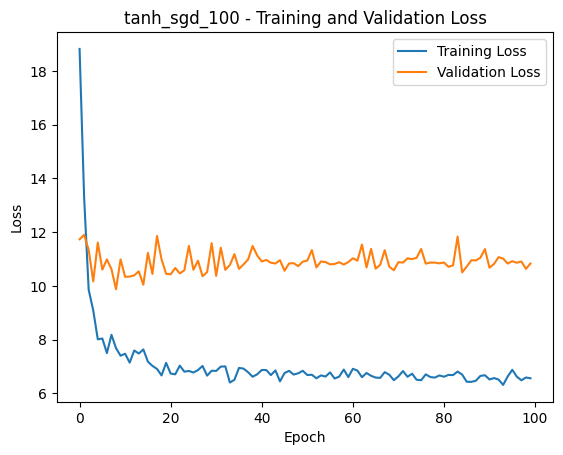

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 18.4237 - val_loss: 10.6283
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 11.4103 - val_loss: 10.7643
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 9.5619 - val_loss: 11.9855
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 8.3588 - val_loss: 10.2553
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.9082 - val_loss: 10.4731
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 8.4041 - val_loss: 10.6512
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.5361 - val_loss: 10.7145
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 7.4779 - val_loss: 10.7460
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.8734 - val_loss: 10.0333
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.5656 - val_loss: 10.1552
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.9906 - val_loss: 10.1378
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/ste

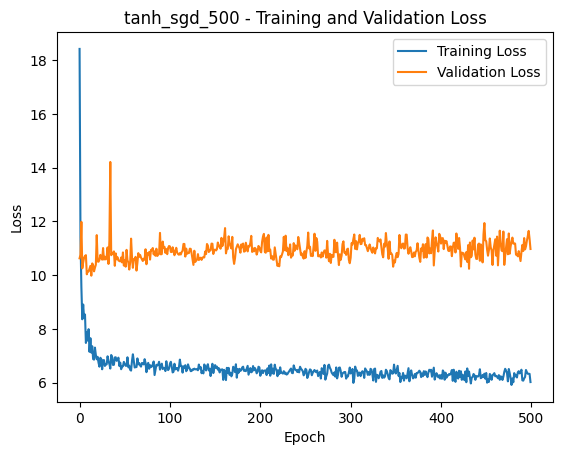

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 23.9132 - val_loss: 14.9050
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 21.1500 - val_loss: 14.7381
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 20.6747 - val_loss: 12.7417
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 19.1335 - val_loss: 13.4504
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 18.5302 - val_loss: 14.4441
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 17.7563 - val_loss: 12.9342
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 16.2146 - val_loss: 13.2996
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 15.4505 - val_loss: 12.6429
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 14.4272 - val_loss: 11.7340
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 13.4489 - val_loss: 10.7703
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 13.1823 - val_loss: 10.4457
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s

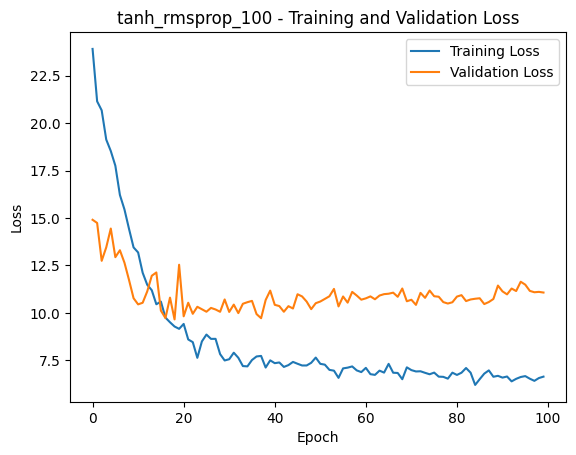

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 23.0919 - val_loss: 16.8908
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 21.1392 - val_loss: 14.9908
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 20.7219 - val_loss: 15.2866
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 19.0690 - val_loss: 12.7660
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 18.7334 - val_loss: 14.0291
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 16.8378 - val_loss: 11.7737
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 16.2873 - val_loss: 13.0436
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 15.8024 - val_loss: 13.2202
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 14.0164 - val_loss: 10.9065
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.2602 - val_loss: 11.4539
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 12.5101 - val_loss: 10.8579
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s

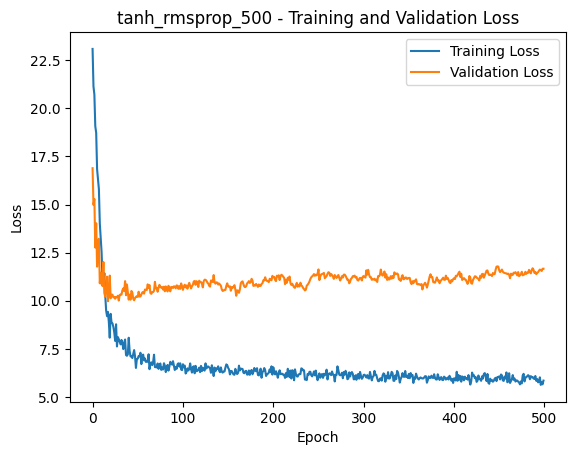

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 23.7262 - val_loss: 26.6557
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 19.7015 - val_loss: 23.4808
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 17.1795 - val_loss: 20.4973
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 14.6738 - val_loss: 18.0279
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.1273 - val_loss: 16.1123
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 11.5140 - val_loss: 14.5873
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 10.3349 - val_loss: 13.3516
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.2607 - val_loss: 12.2620
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 8.5766 - val_loss: 11.3414
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.7779 - val_loss: 10.7554
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 7.5748 - val_loss: 10.4999
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13m

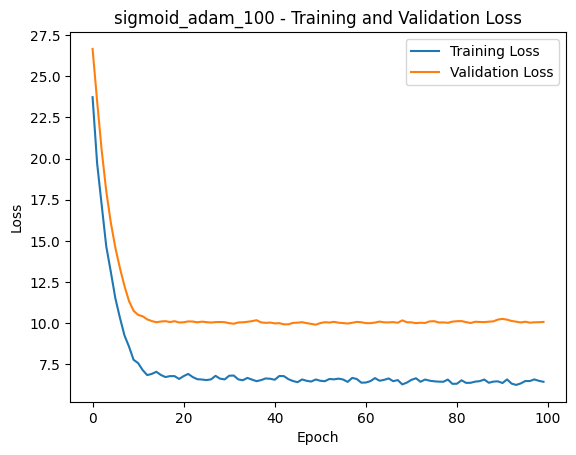

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 21.6927 - val_loss: 24.7301
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 17.9380 - val_loss: 21.2092
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 15.4895 - val_loss: 18.6252
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 13.4075 - val_loss: 16.5030
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 11.5424 - val_loss: 15.0953
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 10.1171 - val_loss: 13.5314
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 9.2015 - val_loss: 12.1786
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 8.2283 - val_loss: 11.4614
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.6982 - val_loss: 11.0030
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.4610 - val_loss: 10.6496
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.1944 - val_loss: 10.3839
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms

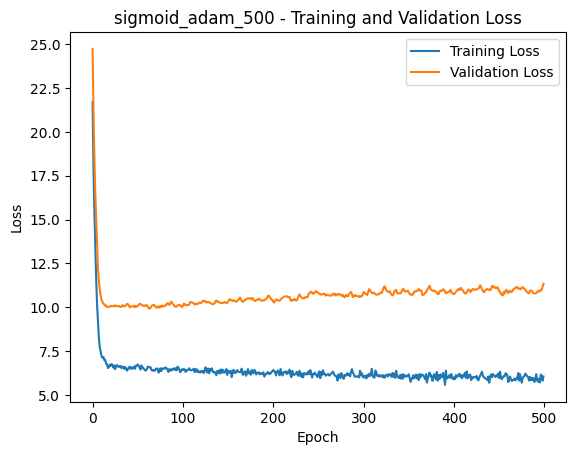

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 9.9019 - val_loss: 10.3495
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.1244 - val_loss: 10.1966
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.2193 - val_loss: 10.7701
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.0944 - val_loss: 10.2496
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.8394 - val_loss: 10.3633
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.8500 - val_loss: 10.8678
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.9936 - val_loss: 10.2184
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.9394 - val_loss: 10.2770
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.9803 - val_loss: 11.9789
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.7714 - val_loss: 11.2350
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.9233 - val_loss: 11.6922
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step 

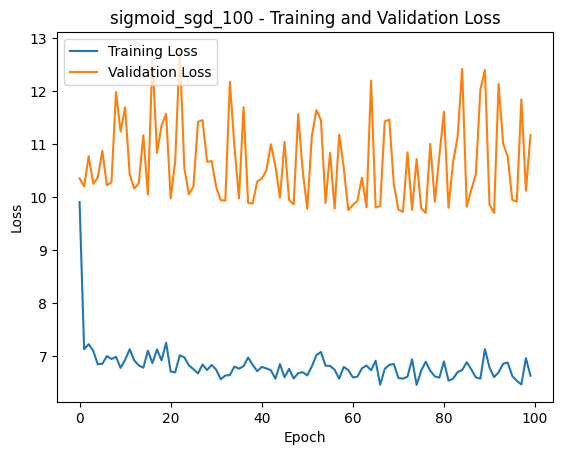

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 8.7003 - val_loss: 10.3874
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.0034 - val_loss: 11.1735
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.9346 - val_loss: 10.1898
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.1674 - val_loss: 11.1351
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.2117 - val_loss: 10.4909
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.9439 - val_loss: 11.9882
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.0886 - val_loss: 10.3793
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.5847 - val_loss: 10.4698
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.5173 - val_loss: 10.1273
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.8971 - val_loss: 10.2366
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.7931 - val_loss: 10.3324
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step 

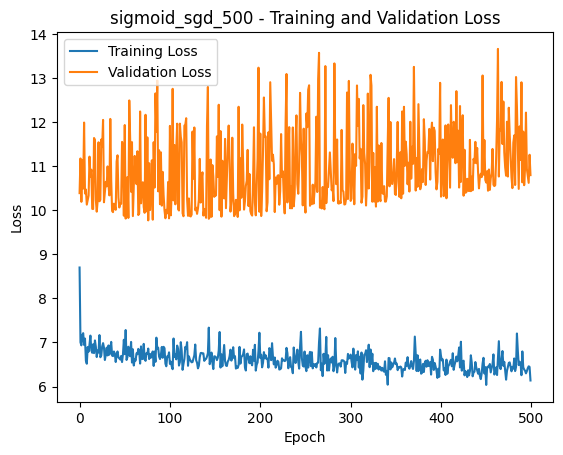

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 23.1001 - val_loss: 23.8578
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 18.8503 - val_loss: 20.8592
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 16.3162 - val_loss: 18.1144
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.2792 - val_loss: 15.7871
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 11.8724 - val_loss: 13.9554
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 10.3017 - val_loss: 12.4880
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.7984 - val_loss: 11.3403
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.1903 - val_loss: 10.8576
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.4797 - val_loss: 10.3785
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 7.1309 - val_loss: 10.1770
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.2143 - val_loss: 10.2542
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/

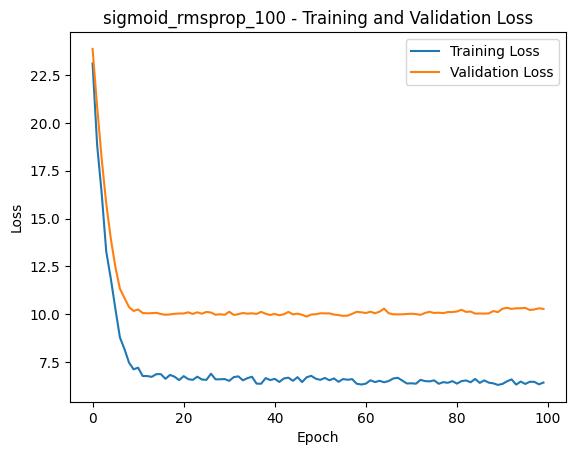

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 10.6585 - val_loss: 12.6507
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 8.5004 - val_loss: 11.3584
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.9203 - val_loss: 11.0112
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.6403 - val_loss: 10.5431
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.1789 - val_loss: 10.4994
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.1155 - val_loss: 10.4129
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.8356 - val_loss: 10.2028
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 6.6520 - val_loss: 10.1092
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.6684 - val_loss: 10.1325
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 6.8068 - val_loss: 10.1228
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.7582 - val_loss: 10.1006
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

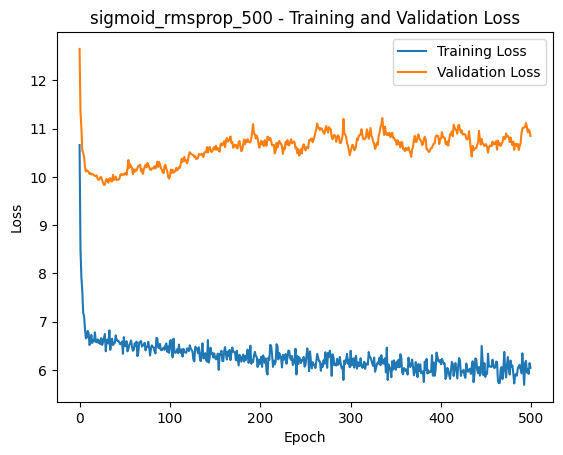

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split  # <-- Add this import
from tensorflow.keras.models import Sequential  # <-- Add this import
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, GaussianNoise  # <-- Updated import

# Assuming you have run the data preparation code and have `data_cleaned`
# Use the cleaned DataFrame for splitting so the model doesn't get NaNs/infs
train_df, temp_df = train_test_split(data_cleaned, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]

# Quick sanity checks: ensure there are no NaNs or infs in inputs/targets
def has_invalid(x):
    return np.isnan(x).any() or np.isinf(x).any()

for name, arr in [('x_train', x_train.values), ('y_train', y_train.values), ('x_val', x_val.values), ('y_val', y_val.values), ('x_test', x_test.values), ('y_test', y_test.values)]:
    if has_invalid(arr):
        raise ValueError(f"Invalid values found in {name} (NaN or Inf). Check data_cleaned and preprocessing.")

# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [100]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            # Use the provided architecture, parameterized by the current activation
            model = Sequential([
                GaussianNoise(0.1, input_shape=(x_train.shape[1],)),
                Dense(256, activation=activation),
                BatchNormalization(),
                Dropout(0.2),
                Dense(128, activation=activation),
                BatchNormalization(),
                Dropout(0.2),
                Dense(64, activation=activation),
                Dense(1)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [4]:
import numpy as np

if not models:
    print('No models found in `models`. Did the training cell run?')
else:
    def _safe_mse(item):
        """Return a numeric MSE for sorting or +inf when unavailable/NaN."""
        v = item[1]
        try:
            # expect v like (model, mse) or (model, mse, history)
            m = v[1]
            m = float(m)
        except Exception:
            m = float('nan')
        return m if not np.isnan(m) else float('inf')

    sorted_models = sorted(models.items(), key=_safe_mse)
    print("Models sorted by Test MSE (lowest to highest):")
    for name, val in sorted_models:
        try:
            mse_val = val[1]
            mse_str = f"{float(mse_val):.6g}"
        except Exception:
            mse_str = 'N/A'
        print(f"{name}: Test MSE = {mse_str}")

Models sorted by Test MSE (lowest to highest):
tanh_adam_500: Test MSE = 6.11154
sigmoid_adam_100: Test MSE = 6.55719
tanh_adam_100: Test MSE = 6.55861
sigmoid_adam_500: Test MSE = 6.70874
sigmoid_rmsprop_100: Test MSE = 6.73171
tanh_sgd_500: Test MSE = 6.75366
tanh_sgd_100: Test MSE = 6.79693
sigmoid_rmsprop_500: Test MSE = 6.79777
tanh_rmsprop_500: Test MSE = 6.93471
tanh_rmsprop_100: Test MSE = 7.00624
sigmoid_sgd_500: Test MSE = 7.10637
sigmoid_sgd_100: Test MSE = 7.91376


Model: tanh_adam_100, Test MSE: 6.935699462890625
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


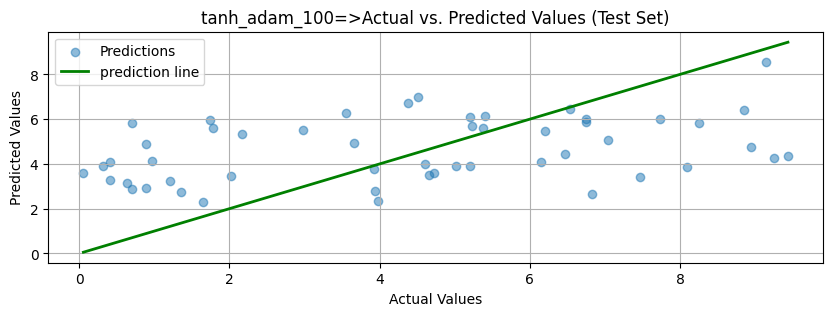

Model: tanh_adam_500, Test MSE: 7.444221019744873
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


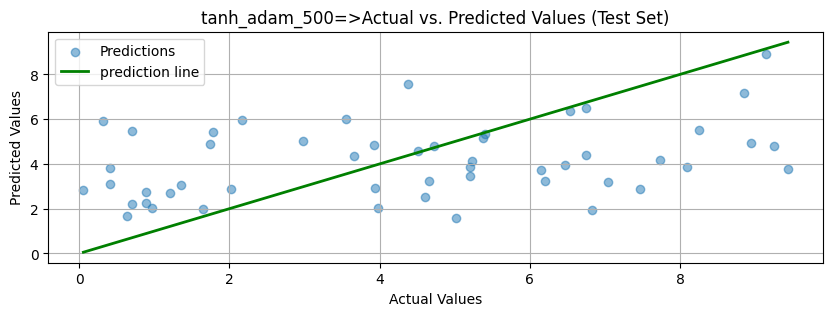

Model: tanh_sgd_100, Test MSE: 6.224243640899658
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7c465c3b89a0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


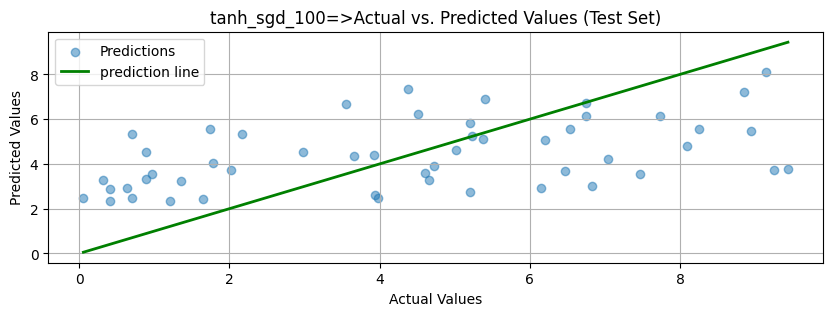

Model: tanh_sgd_500, Test MSE: 7.134983062744141
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


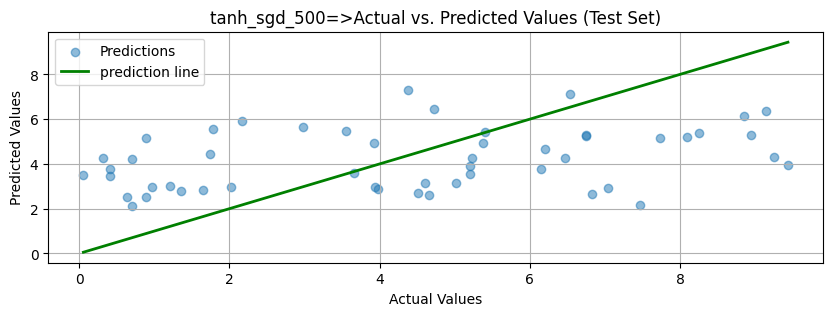

Model: tanh_rmsprop_100, Test MSE: 6.491157054901123
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


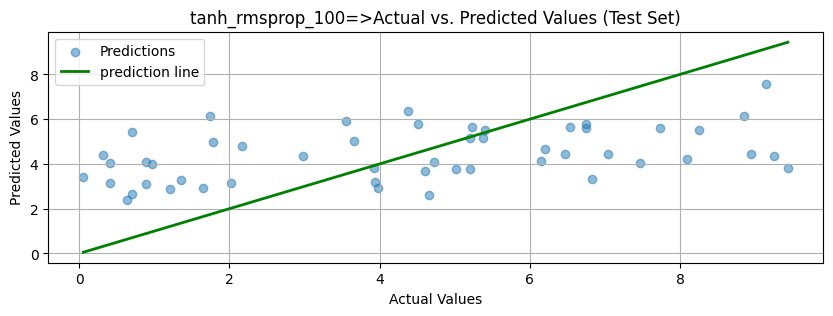

Model: tanh_rmsprop_500, Test MSE: 7.550005912780762
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


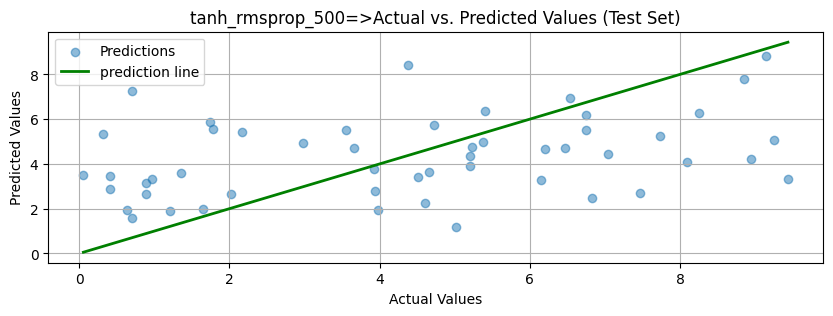

Model: sigmoid_adam_100, Test MSE: 6.429197788238525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


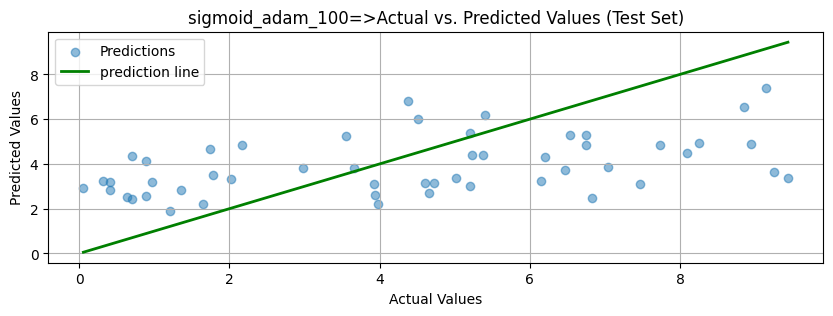

Model: sigmoid_adam_500, Test MSE: 7.158296585083008
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


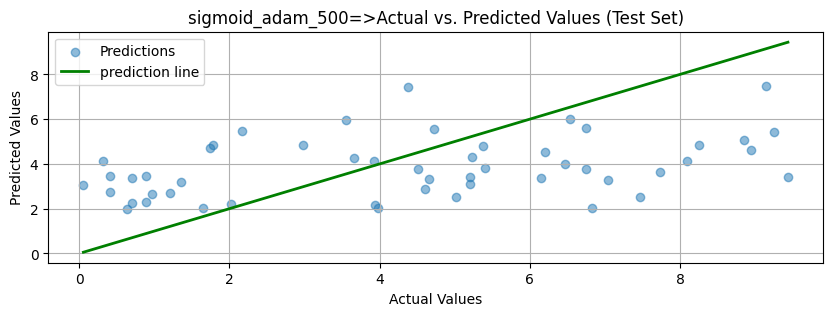

Model: sigmoid_sgd_100, Test MSE: 7.610015392303467
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


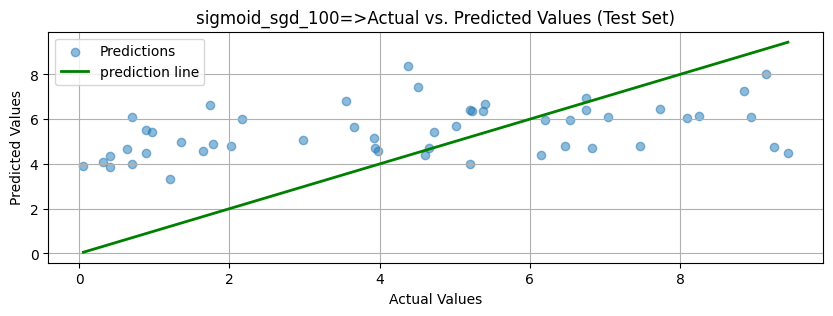

Model: sigmoid_sgd_500, Test MSE: 6.40908145904541
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


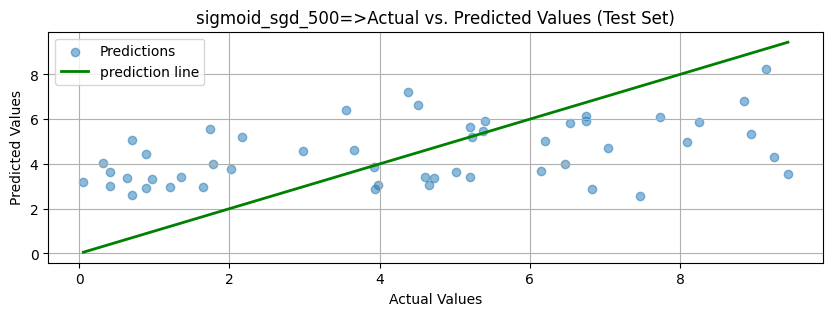

Model: sigmoid_rmsprop_100, Test MSE: 6.219410419464111
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


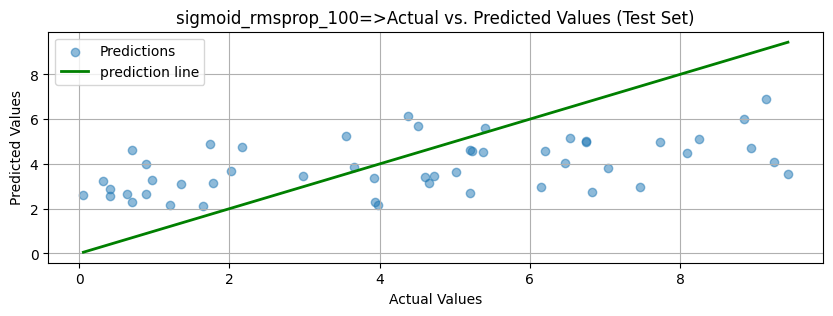

Model: sigmoid_rmsprop_500, Test MSE: 6.873189449310303
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


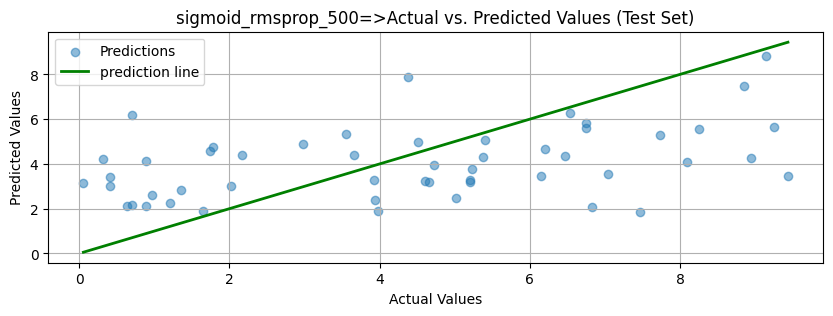

In [5]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")